Using device: cuda
GPU Memory: 8.6 GB
Train: (4800, 256, 256, 3), Val: (1600, 256, 256, 3), Test: (1600, 256, 256, 3)
Batch size: 16, Max epochs: 200, LR: 0.0002
Focus classes: [1, 4, 8, 9]
Early stopping: patience=20, min_epochs=50
Filtered to 1486 samples from classes [1, 4, 8, 9]
Filtered to 495 samples from classes [1, 4, 8, 9]
Generator params: 2,700,051
Discriminator params: 1,587,857

Epoch 1/200


Training: 100%|██████████| 93/93 [00:13<00:00,  7.03it/s]


G Loss: 1.7434, D Loss: 0.5279, Convergence: inf

Epoch 2/200


Training: 100%|██████████| 93/93 [00:09<00:00, 10.24it/s]


G Loss: 2.3061, D Loss: 0.5352, Convergence: inf

Epoch 3/200


Training: 100%|██████████| 93/93 [00:09<00:00, 10.33it/s]


... (391 outputs left out)

Training: 100%|██████████| 93/93 [00:09<00:00, 10.06it/s]


G Loss: 2.9087, D Loss: 0.4093, Convergence: 2.9510

Epoch 200/200


Training: 100%|██████████| 93/93 [00:09<00:00, 10.26it/s]


G Loss: 3.1750, D Loss: 0.2770, Convergence: 3.0024

Reached maximum epochs without full convergence

Training completed in 30.6 minutes
Converged at epoch: 200
Final G Loss: 3.1750, D Loss: 0.2770


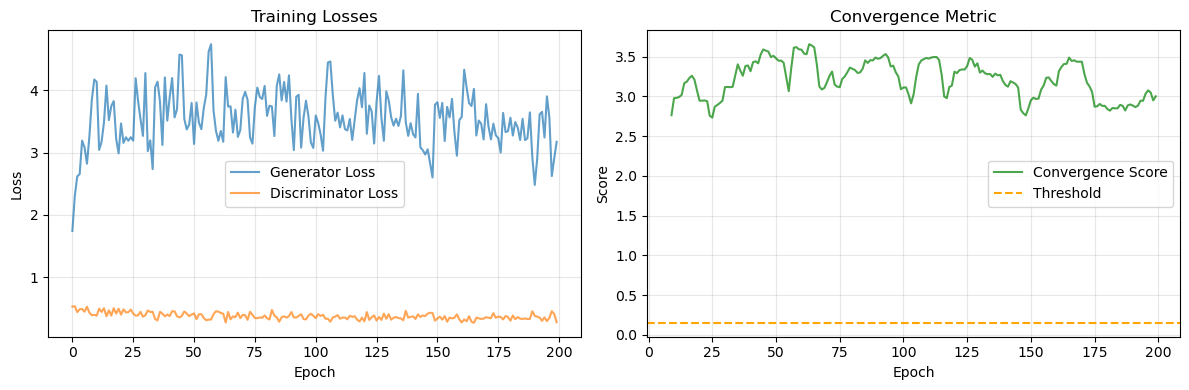


Generating synthetic dataset
Classes: [1, 4, 8, 9], Samples per class: 200
Generating class 1
Generating class 4
Generating class 8
Generating class 9
Shape: (800, 128, 128, 3), Labels: 800


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
from torchvision.utils import save_image, make_grid
import json
import os
from datetime import datetime
import time
from tqdm import tqdm
import gc

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    torch.cuda.empty_cache()

def load_processed_data():
    data_dir = 'data/processed'
    required_files = ['X_train.npy', 'X_val.npy', 'X_test.npy', 
                     'y_train.npy', 'y_val.npy', 'y_test.npy', 'data_info.json']
    
    for file in required_files:
        filepath = os.path.join(data_dir, file)
        if not os.path.exists(filepath):
            raise FileNotFoundError(f"Required file not found: {filepath}")
    
    X_train = np.load(f'{data_dir}/X_train.npy')
    X_val = np.load(f'{data_dir}/X_val.npy')
    X_test = np.load(f'{data_dir}/X_test.npy')
    y_train = np.load(f'{data_dir}/y_train.npy')
    y_val = np.load(f'{data_dir}/y_val.npy')
    y_test = np.load(f'{data_dir}/y_test.npy')
    
    with open(f'{data_dir}/data_info.json', 'r') as f:
        data_info = json.load(f)
    
    print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")
    
    return X_train, X_val, X_test, y_train, y_val, y_test, data_info

X_train, X_val, X_test, y_train, y_val, y_test, data_info = load_processed_data()

class Generator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=4, img_channels=3):
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        
        self.label_emb = nn.Embedding(num_classes, num_classes)
        
        self.init_size = 8
        self.l1 = nn.Linear(latent_dim + num_classes, 256 * self.init_size * self.init_size)
        
        self.conv_blocks = nn.Sequential(
            nn.BatchNorm2d(256),
            
            nn.Upsample(scale_factor=2),
            nn.Conv2d(256, 256, 3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Upsample(scale_factor=2),
            nn.Conv2d(256, 128, 3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, 3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Upsample(scale_factor=2),
            nn.Conv2d(64, 32, 3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(32, img_channels, 3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_emb = self.label_emb(labels)
        gen_input = torch.cat([noise, label_emb], dim=1)
        out = self.l1(gen_input)
        out = out.view(out.shape[0], 256, self.init_size, self.init_size)
        img = self.conv_blocks(out)
        return img

class Discriminator(nn.Module):
    def __init__(self, num_classes=4, img_channels=3):
        super().__init__()
        
        self.label_emb = nn.Embedding(num_classes, num_classes)
        
        def discriminator_block(in_filters, out_filters, bn=True):
            block = [nn.Conv2d(in_filters, out_filters, 3, 2, 1)]
            if bn:
                block.append(nn.BatchNorm2d(out_filters))
            block.append(nn.LeakyReLU(0.2, inplace=True))
            block.append(nn.Dropout2d(0.25))
            return block
        
        self.model = nn.Sequential(
            *discriminator_block(img_channels + num_classes, 64, bn=False),
            *discriminator_block(64, 128),
            *discriminator_block(128, 256),
            *discriminator_block(256, 512),
        )
        
        ds_size = 128 // 2 ** 4
        self.adv_layer = nn.Sequential(
            nn.Linear(512 * ds_size * ds_size, 1),
            nn.Sigmoid()
        )

    def forward(self, img, labels):
        label_emb = self.label_emb(labels)
        label_emb = label_emb.view(label_emb.size(0), label_emb.size(1), 1, 1)
        label_emb = label_emb.expand(label_emb.size(0), label_emb.size(1), img.size(2), img.size(3))
        
        d_in = torch.cat([img, label_emb], dim=1)
        out = self.model(d_in)
        out = out.view(out.shape[0], -1)
        validity = self.adv_layer(out)
        
        return validity

class Galaxy10GANDataset(Dataset):
    def __init__(self, images, labels, focus_classes=None, transform=None):
        if images.dtype != np.uint8:
            self.images = (images * 255).astype(np.uint8)
        else:
            self.images = images
            
        self.labels = labels.astype(np.int64)
        self.transform = transform
        
        if focus_classes is not None:
            mask = np.isin(labels, focus_classes)
            self.images = self.images[mask]
            self.labels = self.labels[mask]
            
            self.label_mapping = {old: new for new, old in enumerate(focus_classes)}
            self.labels = np.array([self.label_mapping[label] for label in self.labels])
            
            print(f"Filtered to {len(self.images)} samples from classes {focus_classes}")
        
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx]
        
        from PIL import Image
        image_pil = Image.fromarray(image)
        
        if self.transform:
            image = self.transform(image_pil)
            image = (image - 0.5) * 2.0
        else:
            image = torch.from_numpy(np.array(image_pil).astype(np.float32))
            image = image.permute(2, 0, 1) / 255.0
            image = (image - 0.5) * 2.0
        
        return image, torch.tensor(label, dtype=torch.long)

def calculate_convergence_metric(g_losses, d_losses, window=10):
    if len(g_losses) < window:
        return float('inf')
    
    recent_g = g_losses[-window:]
    recent_d = d_losses[-window:]
    
    g_std = np.std(recent_g)
    d_std = np.std(recent_d)
    
    g_mean = np.mean(recent_g)
    d_mean = np.mean(recent_d)
    
    balance_score = abs(g_mean - d_mean * 2)
    stability_score = g_std + d_std
    
    return balance_score + stability_score

def train_gan_model():
    torch.cuda.empty_cache()
    gc.collect()
    
    BATCH_SIZE = 16
    MAX_EPOCHS = 200
    LEARNING_RATE = 0.0002
    LATENT_DIM = 100
    
    PATIENCE = 20
    MIN_EPOCHS = 50
    CONVERGENCE_THRESHOLD = 0.15
    
    minority_classes = data_info['minority_classes']
    
    print(f"Batch size: {BATCH_SIZE}, Max epochs: {MAX_EPOCHS}, LR: {LEARNING_RATE}")
    print(f"Focus classes: {minority_classes}")
    print(f"Early stopping: patience={PATIENCE}, min_epochs={MIN_EPOCHS}")
    
    train_transform = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ToTensor()
    ])
    
    val_transform = transforms.Compose([
        transforms.Resize((128, 128)),
        transforms.ToTensor()
    ])
    
    train_dataset = Galaxy10GANDataset(
        X_train, y_train, 
        focus_classes=minority_classes,
        transform=train_transform
    )
    
    val_dataset = Galaxy10GANDataset(
        X_val, y_val,
        focus_classes=minority_classes,
        transform=val_transform
    )
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    generator = Generator(latent_dim=LATENT_DIM, num_classes=len(minority_classes)).to(device)
    discriminator = Discriminator(num_classes=len(minority_classes)).to(device)
    
    adversarial_loss = nn.BCELoss()
    
    optimizer_G = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
    optimizer_D = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
    
    print(f"Generator params: {sum(p.numel() for p in generator.parameters()):,}")
    print(f"Discriminator params: {sum(p.numel() for p in discriminator.parameters()):,}")
    
    g_losses = []
    d_losses = []
    convergence_metrics = []
    
    best_convergence = float('inf')
    epochs_without_improvement = 0
    
    os.makedirs('results/gan', exist_ok=True)
    os.makedirs('results/gan/samples', exist_ok=True)
    
    start_time = time.time()
    converged_epoch = None
    
    for epoch in range(MAX_EPOCHS):
        print(f"\nEpoch {epoch+1}/{MAX_EPOCHS}")
        
        generator.train()
        discriminator.train()
        epoch_g_loss = 0
        epoch_d_loss = 0
        num_batches = 0
        
        for real_imgs, labels in tqdm(train_loader, desc="Training"):
            batch_size = real_imgs.size(0)
            real_imgs = real_imgs.to(device)
            labels = labels.to(device)
            
            valid = torch.ones(batch_size, 1, device=device)
            fake = torch.zeros(batch_size, 1, device=device)
            
            optimizer_G.zero_grad()
            
            z = torch.randn(batch_size, LATENT_DIM, device=device)
            gen_labels = torch.randint(0, len(minority_classes), (batch_size,), device=device)
            
            gen_imgs = generator(z, gen_labels)
            validity = discriminator(gen_imgs, gen_labels)
            g_loss = adversarial_loss(validity, valid)
            
            g_loss.backward()
            optimizer_G.step()
            
            optimizer_D.zero_grad()
            
            real_validity = discriminator(real_imgs, labels)
            d_real_loss = adversarial_loss(real_validity, valid)
            
            fake_validity = discriminator(gen_imgs.detach(), gen_labels)
            d_fake_loss = adversarial_loss(fake_validity, fake)
            
            d_loss = (d_real_loss + d_fake_loss) / 2
            
            d_loss.backward()
            optimizer_D.step()
            
            epoch_g_loss += g_loss.item()
            epoch_d_loss += d_loss.item()
            num_batches += 1
        
        avg_g_loss = epoch_g_loss / num_batches
        avg_d_loss = epoch_d_loss / num_batches
        g_losses.append(avg_g_loss)
        d_losses.append(avg_d_loss)
        
        convergence_score = calculate_convergence_metric(g_losses, d_losses)
        convergence_metrics.append(convergence_score)
        
        print(f"G Loss: {avg_g_loss:.4f}, D Loss: {avg_d_loss:.4f}, Convergence: {convergence_score:.4f}")
        
        if epoch >= MIN_EPOCHS:
            if convergence_score < best_convergence:
                best_convergence = convergence_score
                epochs_without_improvement = 0
                
                torch.save({
                    'epoch': epoch,
                    'generator_state_dict': generator.state_dict(),
                    'discriminator_state_dict': discriminator.state_dict(),
                    'optimizer_G_state_dict': optimizer_G.state_dict(),
                    'optimizer_D_state_dict': optimizer_D.state_dict(),
                    'g_loss': avg_g_loss,
                    'd_loss': avg_d_loss,
                    'convergence_score': convergence_score,
                    'minority_classes': minority_classes
                }, 'results/gan/best_model.pth')
            else:
                epochs_without_improvement += 1
            
            if epochs_without_improvement >= PATIENCE and convergence_score < CONVERGENCE_THRESHOLD:
                converged_epoch = epoch + 1
                print(f"\nConvergence detected at epoch {converged_epoch}")
                print(f"Best convergence score: {best_convergence:.4f}")
                break
        
        if (epoch + 1) % 10 == 0:
            generate_gan_samples(generator, epoch + 1, minority_classes, LATENT_DIM)
        
        torch.cuda.empty_cache()
    
    if converged_epoch is None:
        converged_epoch = MAX_EPOCHS
        print(f"\nReached maximum epochs without full convergence")
    
    training_time = time.time() - start_time
    print(f"\nTraining completed in {training_time/60:.1f} minutes")
    print(f"Converged at epoch: {converged_epoch}")
    print(f"Final G Loss: {g_losses[-1]:.4f}, D Loss: {d_losses[-1]:.4f}")
    
    results = {
        'g_losses': g_losses,
        'd_losses': d_losses,
        'convergence_metrics': convergence_metrics,
        'converged_epoch': converged_epoch,
        'best_convergence_score': float(best_convergence),
        'training_time_minutes': training_time / 60,
        'config': {
            'max_epochs': MAX_EPOCHS,
            'converged_epochs': converged_epoch,
            'batch_size': BATCH_SIZE,
            'learning_rate': LEARNING_RATE,
            'latent_dim': LATENT_DIM,
            'minority_classes': minority_classes,
            'patience': PATIENCE,
            'min_epochs': MIN_EPOCHS
        }
    }
    
    with open('results/gan/training_results.json', 'w') as f:
        json.dump(results, f, indent=2)
    
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(g_losses, label='Generator Loss', alpha=0.7)
    plt.plot(d_losses, label='Discriminator Loss', alpha=0.7)
    if converged_epoch < MAX_EPOCHS:
        plt.axvline(x=converged_epoch-1, color='r', linestyle='--', label='Convergence')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.title('Training Losses')
    plt.grid(True, alpha=0.3)
    
    plt.subplot(1, 2, 2)
    plt.plot(convergence_metrics, label='Convergence Score', color='green', alpha=0.7)
    if converged_epoch < MAX_EPOCHS:
        plt.axvline(x=converged_epoch-1, color='r', linestyle='--', label='Convergence')
    plt.axhline(y=CONVERGENCE_THRESHOLD, color='orange', linestyle='--', label='Threshold')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.legend()
    plt.title('Convergence Metric')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('results/gan/training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return generator, discriminator, results

def generate_gan_samples(generator, epoch, minority_classes, latent_dim, num_samples=8):
    generator.eval()
    
    with torch.no_grad():
        for class_idx, original_class in enumerate(minority_classes):
            z = torch.randn(num_samples, latent_dim, device=device)
            class_labels = torch.full((num_samples,), class_idx, device=device, dtype=torch.long)
            
            samples = generator(z, class_labels)
            
            samples = (samples + 1) / 2
            samples = torch.clamp(samples, 0, 1)
            
            grid = make_grid(samples, nrow=4, padding=2)
            save_image(grid, f'results/gan/samples/epoch_{epoch}_class_{original_class}.png')

generator, discriminator, results = train_gan_model()

def generate_synthetic_dataset_gan(generator, minority_classes, samples_per_class=200, latent_dim=100):
    print(f"\nGenerating synthetic dataset")
    print(f"Classes: {minority_classes}, Samples per class: {samples_per_class}")
    
    generator.eval()
    
    synthetic_images = []
    synthetic_labels = []
    
    with torch.no_grad():
        for class_idx, class_id in enumerate(minority_classes):
            print(f"Generating class {class_id}")
            
            batch_size = 16
            num_batches = (samples_per_class + batch_size - 1) // batch_size
            
            class_samples = []
            
            for batch in range(num_batches):
                current_batch_size = min(batch_size, samples_per_class - batch * batch_size)
                if current_batch_size <= 0:
                    break
                
                z = torch.randn(current_batch_size, latent_dim, device=device)
                class_labels = torch.full((current_batch_size,), class_idx, device=device, dtype=torch.long)
                
                samples = generator(z, class_labels)
                
                samples = (samples + 1) / 2
                samples = torch.clamp(samples, 0, 1)
                
                samples_np = samples.cpu().numpy()
                class_samples.append(samples_np)
                
                batch_labels = np.full(current_batch_size, class_id)
                synthetic_labels.extend(batch_labels)
                
                torch.cuda.empty_cache()
            
            if class_samples:
                class_samples = np.concatenate(class_samples, axis=0)
                synthetic_images.append(class_samples)
    
    synthetic_images = np.concatenate(synthetic_images, axis=0)
    synthetic_labels = np.array(synthetic_labels)
    
    synthetic_images = (synthetic_images * 255).astype(np.uint8)
    synthetic_images = np.transpose(synthetic_images, (0, 2, 3, 1))
    
    print(f"Shape: {synthetic_images.shape}, Labels: {len(synthetic_labels)}")
    
    np.save('results/gan/synthetic_images.npy', synthetic_images)
    np.save('results/gan/synthetic_labels.npy', synthetic_labels)
    
    return synthetic_images, synthetic_labels

torch.save({
    'generator': generator.state_dict(),
    'discriminator': discriminator.state_dict(),
    'minority_classes': [1, 4, 8, 9],
    'label_mapping': {1: 0, 4: 1, 8: 2, 9: 3},
    'latent_dim': 100
}, 'results/gan/complete_gan_model.pth')

synthetic_images, synthetic_labels = generate_synthetic_dataset_gan(
    generator, 
    minority_classes=[1, 4, 8, 9],
    samples_per_class=200,
    latent_dim=100
)